In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv("../data/Dataset.csv")
print(df.head())

  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                 TV Dr

In [3]:
print(df.columns.to_list())

['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [6]:
cluster_df=df[['type','release_year','duration','country','listed_in']].copy()
print('Shape:',cluster_df.shape)
print(cluster_df.head())

Shape: (8790, 5)
      type  release_year  duration        country  \
0    Movie          2020    90 min  United States   
1  TV Show          2021  1 Season         France   
2  TV Show          2021  1 Season  United States   
3    Movie          2021    91 min         Brazil   
4    Movie          1993   125 min  United States   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                 TV Dramas, TV Horror, TV Mysteries  
3                 Children & Family Movies, Comedies  
4   Dramas, Independent Movies, International Movies  


In [7]:
numerical_feature=['release_year']

categorical_feature=['type','duration','country','listed_in']

print('Numerical_feature',numerical_feature)
print('categorical_feature',categorical_feature)

Numerical_feature ['release_year']
categorical_feature ['type', 'duration', 'country', 'listed_in']


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

transform_cluster=ColumnTransformer(transformers=[('cat',OneHotEncoder(handle_unknown='ignore'),categorical_feature),
                                                  ('num',StandardScaler(),numerical_feature)])

print("Clustering preprocessing created Successfully")

Clustering preprocessing created Successfully


In [9]:
X_cluster=transform_cluster.fit_transform(cluster_df)
print("Original shape:", cluster_df.shape)
print("Transformed shape:", X_cluster.shape)

Original shape: (8790, 5)
Transformed shape: (8790, 822)


In [10]:
from sklearn.cluster import KMeans

k_means=KMeans(n_clusters=5,random_state=42,n_init=10)
cluster=k_means.fit_predict(X_cluster)
print("Kmeans Clustering Successfully")
print('cluster labels',cluster[:20])


Kmeans Clustering Successfully
cluster labels [0 1 1 2 4 1 0 2 2 2 2 2 2 0 0 0 0 1 1 0]


In [11]:
cluster_df['cluster']=cluster

count_clusters=cluster_df['cluster'].value_counts().sort_index()
print('Number of Titles in Each Clusters:')
print(count_clusters)

Number of Titles in Each Clusters:
cluster
0    1931
1    2585
2    3274
3     210
4     790
Name: count, dtype: int64


In [12]:

for cluster_id in sorted(cluster_df["cluster"].unique()):
    print(f"\nCluster {cluster_id}:")

    sample = cluster_df[
        cluster_df["cluster"] == cluster_id
    ][["type", "release_year", "duration", "country", "listed_in"]].head(5)

    print(sample.to_string(index=False))



Cluster 0:
 type  release_year duration       country        listed_in
Movie          2020   90 min United States    Documentaries
Movie          2021  104 min United States Comedies, Dramas
Movie          2021   39 min United States           Movies
Movie          2021   36 min United States           Movies
Movie          2021   34 min United States           Movies

Cluster 1:
   type  release_year  duration        country                                                     listed_in
TV Show          2021  1 Season         France Crime TV Shows, International TV Shows, TV Action & Adventure
TV Show          2021  1 Season  United States                            TV Dramas, TV Horror, TV Mysteries
TV Show          2021 9 Seasons United Kingdom                                  British TV Shows, Reality TV
TV Show          2021  1 Season       Pakistan                                        Docuseries, Reality TV
TV Show          2021  1 Season       Pakistan                  British

In [13]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2,random_state=42)
Xpca=pca.fit_transform(X_cluster.toarray())
print("Orginal Shape before PCA of Clusters",X_cluster.shape)
print("After PCA",Xpca.shape)

print("Explained Varience ratio:",pca.explained_variance_ratio_)
print('Total Varience Explained:',pca.explained_variance_ratio_.sum())

Orginal Shape before PCA of Clusters (8790, 822)
After PCA (8790, 2)
Explained Varience ratio: [0.24868625 0.12427214]
Total Varience Explained: 0.37295838974289985


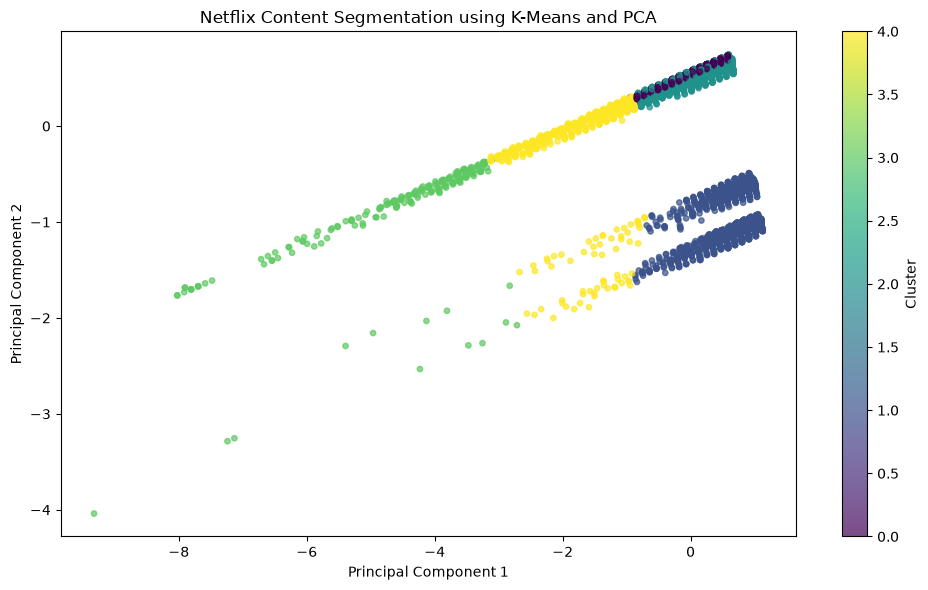

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    Xpca[:, 0],
    Xpca[:, 1],
    c=cluster,
    cmap="viridis",
    s=15,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Netflix Content Segmentation using K-Means and PCA")

plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


In [20]:

for cluster_id in sorted(cluster_df["cluster"].unique()):
    cluster_data = cluster_df[
        cluster_df["cluster"] == cluster_id
    ]
   
    print(f"CLUSTER {cluster_id}")
    print(f"Number of titles: {len(cluster_data)}")

    print("\nContent Type:")
    print(cluster_data["type"].value_counts().head(5))

    print("\nMost Common Countries:")
    print(cluster_data["country"].value_counts().head(5))

    print("\nMost Common Genres:")
    print(cluster_data["listed_in"].value_counts().head(5))

    print("\nAverage Release Year:")
    print(round(cluster_data["release_year"].mean(), 1))

    print("\nCommon Durations:")
    print(cluster_data["duration"].value_counts().head(5))


CLUSTER 0
Number of titles: 1931

Content Type:
type
Movie    1931
Name: count, dtype: int64

Most Common Countries:
country
United States    1931
Name: count, dtype: int64

Most Common Genres:
listed_in
Documentaries                         262
Stand-Up Comedy                       196
Children & Family Movies               88
Children & Family Movies, Comedies     88
Comedies                               76
Name: count, dtype: int64

Average Release Year:
2016.1

Common Durations:
duration
90 min    74
97 min    68
92 min    59
91 min    55
86 min    52
Name: count, dtype: int64
CLUSTER 1
Number of titles: 2585

Content Type:
type
TV Show    2585
Name: count, dtype: int64

Most Common Countries:
country
United States     799
Pakistan          344
United Kingdom    244
South Korea       165
Japan             163
Name: count, dtype: int64

Most Common Genres:
listed_in
Kids' TV                                                  206
International TV Shows, TV Dramas                      